# Step 1: Getting to Know the Data (Data Audit)

**Project:** Can we flag a late order *before* it ships?
**Dataset:** DataCo Smart Supply Chain (Kaggle / Mendeley Data)

### What this notebook does
Before building any model, I want to understand the data well: what each column means, what is missing, what is repeated, and, most importantly, **which columns we are allowed to use**.

### The big idea of my project
Many public notebooks on this dataset report about 99% accuracy for predicting late delivery. When I looked closely, they use the *actual* shipping days as an input. You only know that number **after** the package arrives, so the model is basically reading the answer.

In my project I only use information that is available **at the moment the customer places the order**. That is the realistic situation for a company that wants to act early.

## 1. Setup
This cell installs/imports the libraries. On Google Colab almost everything is already installed.

In [1]:
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
try:
    import kagglehub
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
    import kagglehub

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
print("Running on Colab:", IN_COLAB)

Running on Colab: False


## 2. Load the data
The dataset is public, so `kagglehub` can download it directly. No manual upload is needed.
The file uses special characters (for example in city names), so I read it with `latin-1` encoding.

In [2]:
data_dir = kagglehub.dataset_download("shashwatwork/dataco-smart-supply-chain-for-big-data-analysis")
print("Files:", os.listdir(data_dir))

raw = pd.read_csv(os.path.join(data_dir, "DataCoSupplyChainDataset.csv"), encoding="latin-1")
desc = pd.read_csv(os.path.join(data_dir, "DescriptionDataCoSupplyChain.csv"), encoding="latin-1")

print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")

Files: ['DataCoSupplyChainDataset.csv', 'DescriptionDataCoSupplyChain.csv', 'tokenized_access_logs.csv']


Rows: 180,519   Columns: 53


In [3]:
raw.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


## 3. What does one row mean?
This is important for everything that follows. Is one row one *order*, or one *product inside an order*?

In [4]:
n_rows = len(raw)
n_orders = raw["Order Id"].nunique()
n_customers = raw["Order Customer Id"].nunique()
print(f"Rows (order items): {n_rows:,}")
print(f"Unique orders:      {n_orders:,}")
print(f"Unique customers:   {n_customers:,}")
print(f"Average items per order: {n_rows / n_orders:.2f}")

# Do all items in the same order share the same late/on-time result?
same_outcome = (raw.groupby("Order Id")["Late_delivery_risk"].nunique() == 1).mean()
print(f"Orders where all items have the same late flag: {same_outcome:.0%}")

Rows (order items): 180,519
Unique orders:      65,752
Unique customers:   20,652
Average items per order: 2.75
Orders where all items have the same late flag: 100%


**What I found:** one row is one **product line inside an order**. About 180k rows come from about 66k orders.
All items in an order always share the same late/on-time result.

**Why it matters:** if I split rows randomly into train and test, items from the *same order* end up on both sides.
The model then "recognises" the order instead of learning, and the score looks better than it really is.
So later I will **keep all items of one order together** when splitting.

## 4. Data dictionary + my "allowed to use?" column
The dataset comes with an official description file. I added a column of my own: **is this information known when the order is placed?**
If not, using it to predict late delivery would be cheating (*data leakage*).

In [5]:
desc.columns = ["column", "description"]
desc["column"] = desc["column"].str.strip()
desc["description"] = desc["description"].str.replace(":", "", n=1).str.strip()

not_known_at_order_time = {
    "Days for shipping (real)", "Delivery Status", "Late_delivery_risk",
    "Order Status", "shipping date (DateOrders)",
}
after_the_fact = {"Benefit per order", "Order Profit Per Order", "Order Item Profit Ratio"}
personal_or_useless = {
    "Customer Email", "Customer Password", "Customer Fname", "Customer Lname",
    "Customer Street", "Product Image", "Product Description", "Product Status",
}

def usage(col):
    if col in not_known_at_order_time: return "NO - only known after shipping (leakage)"
    if col in after_the_fact:          return "CAREFUL - calculated after the sale"
    if col in personal_or_useless:     return "DROP - personal info or no information"
    return "YES - known at order time"

desc["use_for_prediction"] = desc["column"].apply(usage)
desc

,column,description,use_for_prediction
0,Type,Type of transaction made,YES - known at order time
1,Days for shipping (real),Actual shipping days of the purchased product,NO - only known after shipping (leakage)
2,Days for shipment (scheduled),Days of scheduled delivery of the purchased pr...,YES - known at order time
3,Benefit per order,Earnings per order placed,CAREFUL - calculated after the sale
4,Sales per customer,Total sales per customer made per customer,YES - known at order time
5,Delivery Status,"Delivery status of orders: Advance shipping , ...",NO - only known after shipping (leakage)
6,Late_delivery_risk,Categorical variable that indicates if sending...,NO - only known after shipping (leakage)
7,Category Id,Product category code,YES - known at order time
8,Category Name,Description of the product category,YES - known at order time
9,Customer City,City where the customer made the purchase,YES - known at order time


In [6]:
desc['use_for_prediction'].value_counts()

use_for_prediction
YES - known at order time                   37
DROP - personal info or no information       8
NO - only known after shipping (leakage)     4
CAREFUL - calculated after the sale          3
Name: count, dtype: int64

## 5. Missing values and duplicates

In [7]:
missing = raw.isna().sum()
missing = missing[missing > 0].to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(raw) * 100).round(2)
print(missing)
print("\nFully duplicated rows:", raw.duplicated().sum())

                     missing_count  missing_pct
Customer Lname                   8         0.00
Customer Zipcode                 3         0.00
Order Zipcode               155679        86.24
Product Description         180519       100.00



Fully duplicated rows: 0


**What I found:**
- `Product Description` is **100% empty** → drop it.
- `Order Zipcode` is about **86% empty** → drop it (we have city, state, country instead).
- `Customer Lname` (8 rows) and `Customer Zipcode` (3 rows) have tiny gaps, and I drop these columns anyway.
- There are **no duplicated rows**.

## 6. Columns that are copies of each other
Some columns have different names but identical values. Keeping both adds nothing and can confuse models.

In [8]:
pairs = [
    ("Benefit per order", "Order Profit Per Order"),
    ("Sales per customer", "Order Item Total"),
    ("Customer Id", "Order Customer Id"),
    ("Order Item Product Price", "Product Price"),
    ("Category Id", "Product Category Id"),
    ("Product Card Id", "Order Item Cardprod Id"),
]
for a, b in pairs:
    identical = (raw[a] == raw[b]).all()
    print(f"{a:28s} vs {b:28s} -> identical: {identical}")

print("\nColumns with only one value:", [c for c in raw.columns if raw[c].nunique(dropna=False) <= 1])

Benefit per order            vs Order Profit Per Order       -> identical: True
Sales per customer           vs Order Item Total             -> identical: True
Customer Id                  vs Order Customer Id            -> identical: True
Order Item Product Price     vs Product Price                -> identical: True
Category Id                  vs Product Category Id          -> identical: True
Product Card Id              vs Order Item Cardprod Id       -> identical: True



Columns with only one value: ['Customer Email', 'Customer Password', 'Product Description', 'Product Status']


## 7. Understanding the target: `Late_delivery_risk`
This is what I want to predict. First, how balanced is it?

Late_delivery_risk
Late (1)               98977
On time / early (0)    81542
Name: count, dtype: int64
Late_delivery_risk
Late (1)               0.548
On time / early (0)    0.452
Name: count, dtype: float64


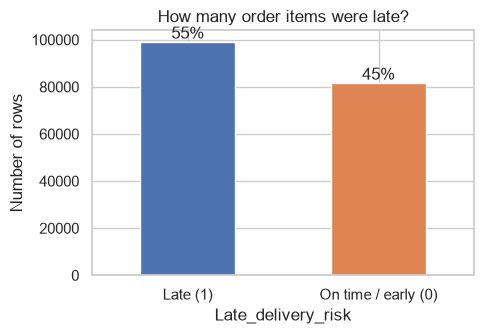

In [9]:
target_counts = raw["Late_delivery_risk"].value_counts().rename({0: "On time / early (0)", 1: "Late (1)"})
print(target_counts)
print((target_counts / target_counts.sum()).round(3))

fig, ax = plt.subplots(figsize=(5, 3.5))
target_counts.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"], rot=0)
ax.set_title("How many order items were late?")
ax.set_ylabel("Number of rows")
for i, v in enumerate(target_counts):
    ax.text(i, v, f"{v/target_counts.sum():.0%}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

**What I found:** about **55% late** vs **45% on time**. This is only *mildly* imbalanced, and it leans toward late.
I will still use class weights later, but this is not a "rare event" problem.

### How is "late" actually defined?
My guess: an order is late when the **real** shipping days are greater than the **scheduled** days. Let me test it.

In [10]:
is_late_by_rule = (raw["Days for shipping (real)"] > raw["Days for shipment (scheduled)"]).astype(int)
matches = is_late_by_rule == raw["Late_delivery_risk"]
print(f"Rule matches on all rows:             {matches.mean():.2%}")

shipped = raw["Delivery Status"] != "Shipping canceled"
print(f"Rule matches on shipped (not canceled): {matches[shipped].mean():.2%}")

pd.crosstab(raw["Delivery Status"], raw["Late_delivery_risk"])

Rule matches on all rows:             97.55%
Rule matches on shipped (not canceled): 100.00%


Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


**What I found (the key finding of this notebook):**
For every order that actually shipped, `Late_delivery_risk` is **exactly** "real days > scheduled days". The only exceptions are canceled orders, which are always marked 0.

**What this means:**
1. Any model that uses `Days for shipping (real)` as an input already knows the answer. That is why some public notebooks show about 99% accuracy.
2. `Delivery Status` ("Late delivery") is just the target written in words. It cannot be an input either.
3. **Canceled orders never ship**, so they don't belong in a late-delivery model. I remove them.

### A first look: does the shipping mode matter?

                scheduled_days  avg_real_days  late_rate    rows
Shipping Mode                                                   
First Class                  1           2.00       1.00   26513
Second Class                 2           3.99       0.80   33806
Same Day                     0           0.48       0.48    9293
Standard Class               4           3.99       0.40  103153


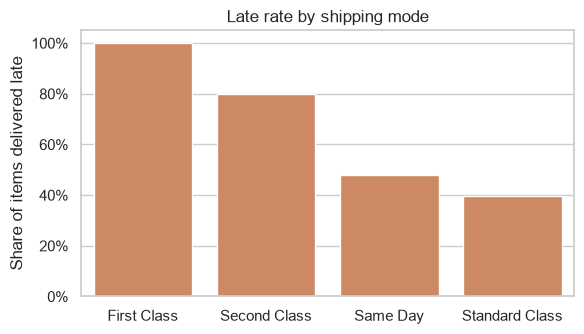

In [11]:
mode_summary = (raw[shipped]
                .groupby("Shipping Mode")
                .agg(scheduled_days=("Days for shipment (scheduled)", "first"),
                     avg_real_days=("Days for shipping (real)", "mean"),
                     late_rate=("Late_delivery_risk", "mean"),
                     rows=("Order Id", "size"))
                .sort_values("late_rate", ascending=False))
display(mode_summary.round(2)) if "display" in dir() else print(mode_summary.round(2))

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=mode_summary.index, y=mode_summary["late_rate"], ax=ax, color="#DD8452")
ax.set_title("Late rate by shipping mode")
ax.set_ylabel("Share of items delivered late"); ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.tight_layout(); plt.show()

**Surprising result:** among orders that actually shipped, **every single First Class order was late**. They always took 2 days, but only 1 day was promised.
Second Class was late about 80% of the time, Same Day about 48%, and Standard Class only about 40%.
The "faster" modes *promise* very few days, and the company can't keep that promise.
I'll dig into this "promise gap" in Step 2 (EDA).

## 8. Time coverage

First order: 2015-01-01   Last order: 2018-01-31


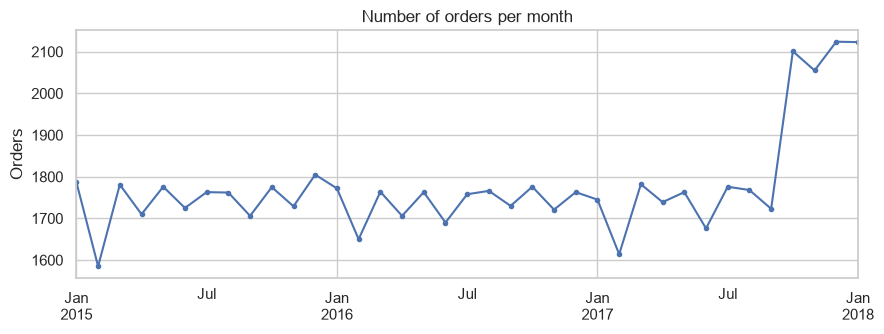

In [12]:
order_date = pd.to_datetime(raw["order date (DateOrders)"])
print("First order:", order_date.min().date(), "  Last order:", order_date.max().date())

monthly = raw.groupby(order_date.dt.to_period("M"))["Order Id"].nunique()
fig, ax = plt.subplots(figsize=(9, 3.5))
monthly.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Number of orders per month")
ax.set_ylabel("Orders"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**What I found:** the data covers **Jan 2015 – Jan 2018**. Volume is steady until about **October 2017**, then drops sharply. The last months are probably incomplete.
**Plan:** for testing my models I will use a **time-based split**: train on older orders, test on newer ones. That is how a model would be used in real life, predicting the future from the past. I'll keep the thin final months in mind when choosing the cut-off.

## 9. Cleaning
Based on everything above:
1. Drop personal information (email, password, names, street). It isn't needed and shouldn't be shared.
2. Drop empty or constant columns and the duplicate columns.
3. Convert the date columns to real dates and add simple date features (year, month, weekday, hour).
4. Flag canceled and suspected-fraud orders so later steps can exclude them.
5. Make column names short and code-friendly.

In [13]:
drop_cols = [
    # personal / no information
    "Customer Email", "Customer Password", "Customer Fname", "Customer Lname", "Customer Street",
    "Product Image", "Product Description", "Product Status", "Order Zipcode",
    # exact duplicates of other columns
    "Order Profit Per Order", "Sales per customer", "Order Customer Id",
    "Order Item Product Price", "Product Category Id", "Order Item Cardprod Id",
]
df = raw.drop(columns=drop_cols).copy()

rename = {
    "Type": "payment_type",
    "Days for shipping (real)": "days_real",
    "Days for shipment (scheduled)": "days_scheduled",
    "Benefit per order": "profit",
    "Delivery Status": "delivery_status",
    "Late_delivery_risk": "late",
    "Category Id": "category_id", "Category Name": "category",
    "Customer City": "customer_city", "Customer Country": "customer_country",
    "Customer Id": "customer_id", "Customer Segment": "customer_segment",
    "Customer State": "customer_state", "Customer Zipcode": "customer_zipcode",
    "Department Id": "department_id", "Department Name": "department",
    "Latitude": "store_lat", "Longitude": "store_lon",
    "Market": "market", "Order City": "order_city", "Order Country": "order_country",
    "order date (DateOrders)": "order_date", "Order Id": "order_id",
    "Order Item Discount": "discount", "Order Item Discount Rate": "discount_rate",
    "Order Item Id": "item_id", "Order Item Profit Ratio": "profit_ratio",
    "Order Item Quantity": "quantity", "Sales": "gross_sales", "Order Item Total": "net_sales",
    "Order Region": "order_region", "Order State": "order_state", "Order Status": "order_status",
    "Product Card Id": "product_id", "Product Name": "product", "Product Price": "price",
    "shipping date (DateOrders)": "ship_date", "Shipping Mode": "shipping_mode",
}
df = df.rename(columns=rename)

df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["order_weekday"] = df["order_date"].dt.day_name()
df["order_hour"] = df["order_date"].dt.hour

df["is_canceled"] = df["delivery_status"].eq("Shipping canceled")
df["is_fraud"] = df["order_status"].eq("SUSPECTED_FRAUD")
df["delay_gap"] = df["days_real"] - df["days_scheduled"]   # used only as a target / for analysis
df["is_loss"] = df["profit"] < 0

print("Clean shape:", df.shape)
print("Canceled rows:", df["is_canceled"].sum(), "| Fraud rows:", df["is_fraud"].sum(),
      "| Overlap:", (df["is_canceled"] & df["is_fraud"]).sum())
df.head()

Clean shape: (180519, 46)
Canceled rows: 7754 | Fraud rows: 4062 | Overlap: 4062


,payment_type,days_real,days_scheduled,profit,delivery_status,late,category_id,category,customer_city,customer_country,customer_id,customer_segment,customer_state,customer_zipcode,department_id,department,store_lat,store_lon,market,order_city,order_country,order_date,order_id,discount,discount_rate,item_id,profit_ratio,quantity,gross_sales,net_sales,order_region,order_state,order_status,product_id,product,price,ship_date,shipping_mode,order_year,order_month,order_weekday,order_hour,is_canceled,is_fraud,delay_gap,is_loss
0,DEBIT,3,4,91.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,20755,Consumer,PR,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,2018-01-31 22:56:00,77202,13.110000,0.04,180517,0.29,1,327.75,314.640015,Southeast Asia,Java Occidental,COMPLETE,1360,Smart watch,327.75,2018-02-03 22:56:00,Standard Class,2018,1,Wednesday,22,False,False,-1,False
1,TRANSFER,5,4,-249.089996,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,PR,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,2018-01-13 12:27:00,75939,16.389999,0.05,179254,-0.80,1,327.75,311.359985,South Asia,Rajastán,PENDING,1360,Smart watch,327.75,2018-01-18 12:27:00,Standard Class,2018,1,Saturday,12,False,False,1,True
2,CASH,4,4,-247.779999,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,19491,Consumer,CA,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,2018-01-13 12:06:00,75938,18.030001,0.06,179253,-0.80,1,327.75,309.720001,South Asia,Rajastán,CLOSED,1360,Smart watch,327.75,2018-01-17 12:06:00,Standard Class,2018,1,Saturday,12,False,False,0,True
3,DEBIT,3,4,22.860001,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,19490,Home Office,CA,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,2018-01-13 11:45:00,75937,22.940001,0.07,179252,0.08,1,327.75,304.809998,Oceania,Queensland,COMPLETE,1360,Smart watch,327.75,2018-01-16 11:45:00,Standard Class,2018,1,Saturday,11,False,False,-1,False
4,PAYMENT,2,4,134.210007,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,19489,Corporate,PR,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,2018-01-13 11:24:00,75936,29.500000,0.09,179251,0.45,1,327.75,298.250000,Oceania,Queensland,PENDING_PAYMENT,1360,Smart watch,327.75,2018-01-15 11:24:00,Standard Class,2018,1,Saturday,11,False,False,-2,False


**Note:** every suspected-fraud row is also a canceled row, so removing canceled orders removes fraud too.

## 10. Order-level table
Because the late flag belongs to the whole **order**, I also build a table with **one row per order**. It will be useful for modelling and clustering.

In [14]:
orders = (df.groupby("order_id")
            .agg(order_date=("order_date", "first"),
                 customer_id=("customer_id", "first"),
                 customer_segment=("customer_segment", "first"),
                 market=("market", "first"),
                 order_region=("order_region", "first"),
                 order_country=("order_country", "first"),
                 shipping_mode=("shipping_mode", "first"),
                 payment_type=("payment_type", "first"),
                 days_scheduled=("days_scheduled", "first"),
                 days_real=("days_real", "first"),
                 late=("late", "first"),
                 is_canceled=("is_canceled", "first"),
                 is_fraud=("is_fraud", "first"),
                 n_items=("item_id", "count"),
                 total_quantity=("quantity", "sum"),
                 gross_sales=("gross_sales", "sum"),
                 net_sales=("net_sales", "sum"),
                 total_discount=("discount", "sum"),
                 profit=("profit", "sum"),
                 n_categories=("category", "nunique"))
            .reset_index())
orders["avg_discount_rate"] = orders["total_discount"] / orders["gross_sales"]
orders["profit_margin"] = orders["profit"] / orders["net_sales"]
orders["delay_gap"] = orders["days_real"] - orders["days_scheduled"]
print("Orders table:", orders.shape)
orders.head()

Orders table: (65752, 24)


,order_id,order_date,customer_id,customer_segment,market,order_region,order_country,shipping_mode,payment_type,days_scheduled,days_real,late,is_canceled,is_fraud,n_items,total_quantity,gross_sales,net_sales,total_discount,profit,n_categories,avg_discount_rate,profit_margin,delay_gap
0,1,2015-01-01 00:00:00,11599,Consumer,LATAM,Central America,México,Standard Class,CASH,4,2,0,False,False,1,1,299.980011,239.979996,60.000000,88.790001,1,0.200013,0.369989,-2
1,2,2015-01-01 00:21:00,256,Consumer,LATAM,South America,Colombia,Standard Class,PAYMENT,4,3,0,False,False,3,7,579.980011,529.380005,50.600000,195.900002,3,0.087244,0.370056,-1
2,4,2015-01-01 01:03:00,8827,Home Office,LATAM,South America,Colombia,Standard Class,CASH,4,5,1,False,False,4,14,699.850010,620.870014,78.980000,124.090000,4,0.112853,0.199865,1
3,5,2015-01-01 01:24:00,11318,Consumer,LATAM,South America,Colombia,Standard Class,DEBIT,4,6,1,False,False,5,10,1129.860039,987.070007,142.789999,390.089995,4,0.126378,0.395200,2
4,7,2015-01-01 02:06:00,4530,Consumer,LATAM,South America,Brasil,Second Class,DEBIT,2,3,1,False,False,3,7,579.920013,525.520004,54.400000,203.929998,3,0.093806,0.388054,1


## 11. Save the cleaned data
On Colab, files saved in `/content` disappear when the session ends. If you set `SAVE_TO_DRIVE = True`, the files are saved to your Google Drive so the next notebooks can load them. Colab will ask you to allow Drive access the first time.

In [15]:
SAVE_TO_DRIVE = False   # change to True on Colab to keep the files between sessions

if IN_COLAB and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    out_dir = "/content/drive/MyDrive/dataco-final-project/processed"
elif IN_COLAB:
    out_dir = "/content/dataco-final-project/processed"
else:
    out_dir = os.path.join("..", "data", "processed")
os.makedirs(out_dir, exist_ok=True)

df.to_parquet(os.path.join(out_dir, "items_clean.parquet"), index=False)
orders.to_parquet(os.path.join(out_dir, "orders_clean.parquet"), index=False)
desc.to_csv(os.path.join(out_dir, "data_dictionary_with_usage.csv"), index=False)
print("Saved to:", os.path.abspath(out_dir))
print(os.listdir(out_dir))

Saved to: C:\Users\emraa\Downloads\claude work\dataco-final-project\data\processed
['data_dictionary_with_usage.csv', 'items_clean.parquet', 'orders_clean.parquet']


## Summary: what I learned in Step 1

| # | Finding | What I will do about it |
|---|---|---|
| 1 | 180,519 rows = product lines from **65,752 orders** and 20,652 customers | Keep all items of one order together when splitting train/test |
| 2 | `Late_delivery_risk` is exactly "real days > scheduled days" | **Never** use real shipping days or delivery status as inputs (leakage) |
| 3 | Target is 55% late / 45% on time | Mild imbalance → class weights; focus on **recall** for late orders |
| 4 | Canceled orders (7,754 rows, which include all 4,062 suspected-fraud rows) are always marked "not late" | Remove canceled orders from the delivery models |
| 5 | Shipped First Class orders are late 100% of the time (2 days vs 1 promised); Standard is late about 40% | Explore the "promise gap" in Step 2 |
| 6 | 6 pairs of duplicate columns, 3 empty/constant columns, personal data | Dropped |
| 7 | Data covers 2015–Jan 2018; volume drops after Oct 2017 | Use a time-based train/test split |

**Next step:** Step 2, exploratory analysis: *why* are orders late, and which orders lose money?